In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, label_binarize
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc

RANDOM_STATE = 42
TARGET = "popularity_category"

# Загружаем данные
df = pd.read_csv("spotify_artist_streaming_2020_2025.csv")
df = df.dropna(subset=[TARGET]).copy()

# Убираем идентификаторы, текст и целевую переменную, чтобы не было утечки данных
drop_cols = ["track_id", "track_name", "artist_name", "album_name", "release_date", TARGET]
if TARGET == "popularity_category":
    drop_cols.append("popularity")

X = df.drop(columns=drop_cols, errors="ignore").copy()
y = df[TARGET].copy()

# Приводим bool к int
bool_cols = X.select_dtypes(include=["bool"]).columns
X[bool_cols] = X[bool_cols].astype(int)

# Делим на train и test (сохраняем пропорции классов через stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

# Определяем числовые и категориальные признаки
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

# Настраиваем конвейер предобработки
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ],
    remainder="drop"
)

print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)
print("Классы:", np.unique(y_train))

Размер train: (37500, 26)
Размер test: (12500, 26)
Классы: ['High' 'Low' 'Medium' 'Very High']


In [2]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

rf_pipe = Pipeline(steps=[
    ("prep", preprocess),
    ("rf", rf)
])

# Обучение
rf_pipe.fit(X_train, y_train)

# Вывод OOB-метрик
oob_acc = rf_pipe.named_steps["rf"].oob_score_
print(f"OOB Accuracy: {oob_acc:.4f}")
print(f"OOB Error: {1 - oob_acc:.4f}")

# Исправленный вывод OOB-предсказаний
oob_proba = rf_pipe.named_steps["rf"].oob_decision_function_
oob_predictions = rf_pipe.named_steps["rf"].classes_[np.argmax(oob_proba, axis=1)]

print("OOB predictions, первые 10 значений:")
print(oob_predictions[:10])

# Проверка на тестовой выборке
y_pred_rf = rf_pipe.predict(X_test)
print("\nRandom Forest, качество на тестовой выборке:")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print(classification_report(y_test, y_pred_rf, zero_division=0))

OOB Accuracy: 0.7944
OOB Error: 0.2056
OOB predictions, первые 10 значений:
['Medium' 'Medium' 'High' 'Medium' 'Medium' 'Low' 'Medium' 'Low' 'Low'
 'Low']

Random Forest, качество на тестовой выборке:
Accuracy: 0.7953
              precision    recall  f1-score   support

        High       0.74      0.63      0.68      1295
         Low       0.84      0.85      0.85      5817
      Medium       0.76      0.79      0.77      5326
   Very High       0.00      0.00      0.00        62

    accuracy                           0.80     12500
   macro avg       0.58      0.57      0.57     12500
weighted avg       0.79      0.80      0.79     12500



In [3]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

# --- 1. AdaBoost ---
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
    n_estimators=300,
    learning_rate=0.5,
    algorithm="SAMME", # Важно для новых версий sklearn
    random_state=RANDOM_STATE
)

ada_pipe = Pipeline(steps=[
    ("prep", preprocess),
    ("ada", ada)
])

ada_pipe.fit(X_train, y_train)
y_pred_ada = ada_pipe.predict(X_test)

print("=" * 70)
print("AdaBoost")
print("Accuracy:", round(accuracy_score(y_test, y_pred_ada), 4))
print(classification_report(y_test, y_pred_ada, zero_division=0))

# --- 2. Градиентный бустинг ---
gb = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE
)

gb_pipe = Pipeline(steps=[
    ("prep", preprocess),
    ("gb", gb)
])

gb_pipe.fit(X_train, y_train)
y_pred_gb = gb_pipe.predict(X_test)

print("=" * 70)
print("Gradient Boosting")
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 4))
print(classification_report(y_test, y_pred_gb, zero_division=0))

C:\Users\danii\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


AdaBoost
Accuracy: 0.7842
              precision    recall  f1-score   support

        High       0.69      0.66      0.68      1295
         Low       0.83      0.86      0.84      5817
      Medium       0.76      0.74      0.75      5326
   Very High       0.11      0.08      0.09        62

    accuracy                           0.78     12500
   macro avg       0.60      0.59      0.59     12500
weighted avg       0.78      0.78      0.78     12500

Gradient Boosting
Accuracy: 0.7966
              precision    recall  f1-score   support

        High       0.75      0.62      0.68      1295
         Low       0.84      0.86      0.85      5817
      Medium       0.76      0.78      0.77      5326
   Very High       0.46      0.31      0.37        62

    accuracy                           0.80     12500
   macro avg       0.70      0.64      0.67     12500
weighted avg       0.80      0.80      0.80     12500



Random Forest: per-class AUC = {'High': np.float64(0.961), 'Low': np.float64(0.936), 'Medium': np.float64(0.873), 'Very High': np.float64(0.994)}
AdaBoost: per-class AUC = {'High': np.float64(0.949), 'Low': np.float64(0.927), 'Medium': np.float64(0.774), 'Very High': np.float64(0.989)}
Gradient Boosting: per-class AUC = {'High': np.float64(0.964), 'Low': np.float64(0.939), 'Medium': np.float64(0.879), 'Very High': np.float64(0.991)}


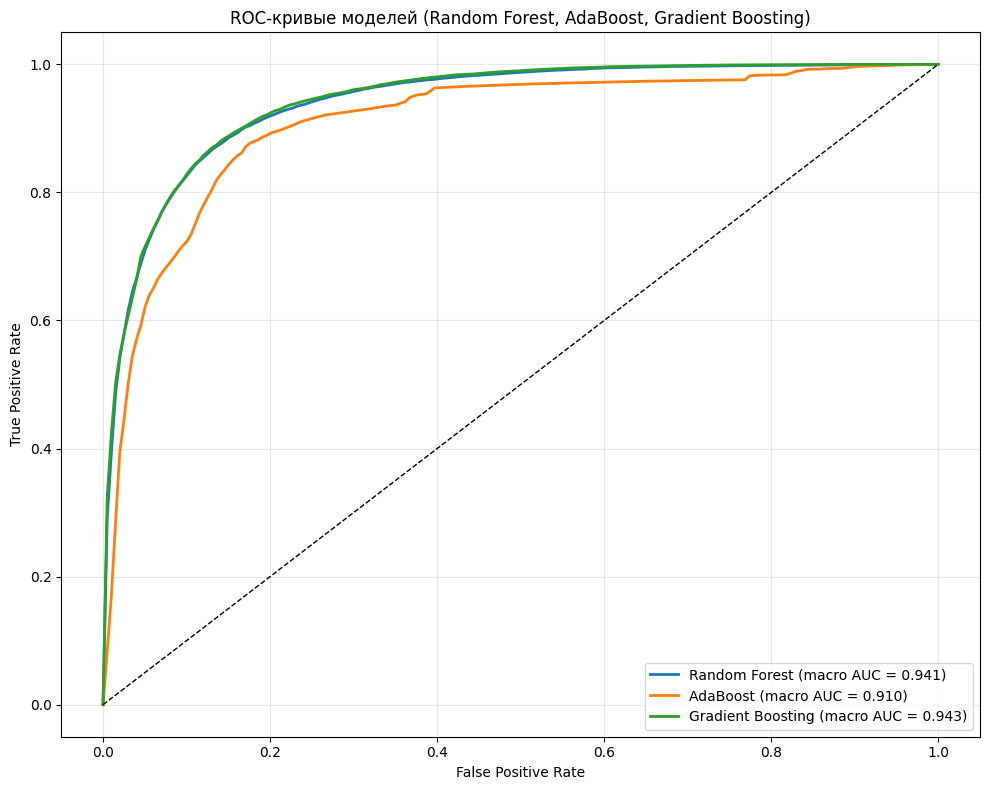

In [4]:
models = {
    "Random Forest": rf_pipe,
    "AdaBoost": ada_pipe,
    "Gradient Boosting": gb_pipe
}

classes = np.unique(y_train)
n_classes = len(classes)

# Бинаризация меток для мультиклассовой ROC-кривой
if n_classes == 2:
    y_test_bin = (y_test == classes[1]).astype(int)
else:
    y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(10, 8))
mean_fpr = np.linspace(0, 1, 200)

for name, model in models.items():
    proba = model.predict_proba(X_test)
    model_classes = model.steps[-1][1].classes_

    # Синхронизация порядка классов
    if not np.array_equal(model_classes, classes):
        proba = proba[:, [list(model_classes).index(c) for c in classes]]

    if n_classes == 2:
        fpr, tpr, _ = roc_curve(y_test_bin, proba[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.3f})")
    else:
        tprs = []
        aucs = []
        
        # Считаем ROC для каждого класса отдельно (One-vs-Rest)
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
            aucs.append(auc(fpr, tpr))
            
            interp_tpr = np.interp(mean_fpr, fpr, tpr)
            interp_tpr[0] = 0.0
            tprs.append(interp_tpr)
            
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[-1] = 1.0
        macro_auc = auc(mean_fpr, mean_tpr)
        
        plt.plot(mean_fpr, mean_tpr, lw=2, label=f"{name} (macro AUC = {macro_auc:.3f})")
        print(f"{name}: per-class AUC = {dict(zip(classes, np.round(aucs, 3)))}")

# Оформление графика
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые моделей (Random Forest, AdaBoost, Gradient Boosting)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# Сохранение графика для отчета
plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()